[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Shreyashgol/phonetic-guided-speech-generation/blob/main/notebooks/12_train_acoustic_model.ipynb)

# 12 · Train the acoustic model
**Goal:** train the model from notebook 11 on all training utterances, with checkpoints on Drive so training **resumes** after a Colab disconnect.

**Use a GPU:** Runtime -> Change runtime type -> T4. Rerun the notebook after a disconnect; it continues from `last.pt`.

**Design decisions (put these in the report)**
- **Optimiser:** AdamW, peak LR 5e-4, 1,000 warm-up steps then inverse-square-root decay (the usual Transformer schedule), gradient clipping at 1.0.
- **Batches grouped by length** (bucketing) so little compute is wasted on padding.
- **Mixed precision** (fp16) on GPU for speed; the loss is computed in fp32.
- **Selection:** the best checkpoint is chosen on **validation** mel L1 only. The test set is not touched until notebook 14.
- **Time budget:** the loop stops cleanly after `minutes_budget` and saves, so a session never ends mid-write.
- **Validation** uses ground-truth durations (teacher forcing) and also reports the duration head's own error in frames.

**Reads:** notebook 10 outputs. **Writes:** `checkpoints/acoustic/{last,best}.pt`, `results/12_train_log.csv`, `results/12_val_log.csv`, `results/12_curves.png`.

In [ ]:
# ---- Cell 0: Setup (identical at the top of every notebook)
import os, sys, json, glob
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/phonetic-tts'
    IN_COLAB = True
except ImportError:                      # running somewhere else (local / tests)
    PROJECT_ROOT = os.environ.get('PROJECT_ROOT', os.getcwd())
    IN_COLAB = False
sys.path.insert(0, PROJECT_ROOT)
from src.utils.config import load_config
cfg = load_config(PROJECT_ROOT)
A = cfg['audio']; P = cfg['abs_paths']
RAW, PROCESSED, ALIGN, SPLITS, RESULTS = P['raw'], P['processed'], P['alignments'], P['splits'], P['results']
for d in (PROCESSED, ALIGN, SPLITS, RESULTS):
    os.makedirs(d, exist_ok=True)
print('Project root:', PROJECT_ROOT, '| Colab:', IN_COLAB)

Mounted at /content/drive
Project root: /content/drive/MyDrive/phonetic-tts | Colab: True


In [ ]:
# ---- Write shared module: Phase 2 dataset, collate and bucket sampler
import os, importlib
_src = r'''"""Phase 2 data loading: manifest + mels from notebook 10."""
import json, os
import numpy as np, pandas as pd, torch
from torch.utils.data import Dataset, Sampler


class TTSDataset(Dataset):
    def __init__(self, processed_dir, split, max_items=None):
        df = pd.read_csv(os.path.join(processed_dir, 'phase2_manifest.csv'))
        df = df[df.split == split].reset_index(drop=True)
        if max_items: df = df.iloc[:max_items]
        st = json.load(open(os.path.join(processed_dir, 'mel_stats.json')))
        self.mean = np.array(st['mean'], np.float32); self.std = np.array(st['std'], np.float32) + 1e-5
        self.mel_dir = os.path.join(processed_dir, 'mels')
        self.ids = df.utt_id.tolist(); self.n_frames = df.n_frames.to_numpy()
        self.tokens = [np.array(s.split(), np.int64) for s in df.tokens]
        self.stress = [np.array(s.split(), np.int64) for s in df.stress]
        self.durs = [np.array(s.split(), np.int64) for s in df.durations]

    def __len__(self):
        return len(self.ids)

    def mel(self, i):
        m = np.load(os.path.join(self.mel_dir, self.ids[i] + '.npy')).astype(np.float32)
        return (m - self.mean) / self.std

    def __getitem__(self, i):
        return dict(id=self.ids[i], tok=torch.from_numpy(self.tokens[i]), stress=torch.from_numpy(self.stress[i]),
                    dur=torch.from_numpy(self.durs[i]), mel=torch.from_numpy(self.mel(i)))


def collate(batch):
    B = len(batch); T = max(len(b['tok']) for b in batch); M = max(len(b['mel']) for b in batch)
    n_mels = batch[0]['mel'].shape[1]
    tok = torch.zeros(B, T, dtype=torch.long); st = torch.zeros(B, T, dtype=torch.long)
    dur = torch.zeros(B, T, dtype=torch.long); mel = torch.zeros(B, M, n_mels)
    for i, b in enumerate(batch):
        t, m = len(b['tok']), len(b['mel'])
        tok[i, :t] = b['tok']; st[i, :t] = b['stress']; dur[i, :t] = b['dur']; mel[i, :m] = b['mel']
    return dict(ids=[b['id'] for b in batch], tok=tok, stress=st, dur=dur, mel=mel,
                mel_len=torch.tensor([len(b['mel']) for b in batch]))


class BucketSampler(Sampler):
    """Batches of similar length (less padding), shuffled each epoch."""
    def __init__(self, n_frames, batch_size, shuffle=True, seed=0):
        self.n = np.asarray(n_frames); self.bs = batch_size; self.shuffle = shuffle; self.epoch = 0; self.seed = seed

    def __iter__(self):
        rng = np.random.RandomState(self.seed + self.epoch); self.epoch += 1
        idx = rng.permutation(len(self.n)) if self.shuffle else np.arange(len(self.n))
        chunk = self.bs * 50
        batches = []
        for s in range(0, len(idx), chunk):
            c = idx[s:s + chunk]; c = c[np.argsort(self.n[c])]
            batches += [c[j:j + self.bs].tolist() for j in range(0, len(c), self.bs)]
        if self.shuffle: rng.shuffle(batches)
        return iter(batches)

    def __len__(self):
        return (len(self.n) + self.bs - 1) // self.bs
'''
_p = os.path.join(PROJECT_ROOT, "src/data/tts_dataset.py")
os.makedirs(os.path.dirname(_p), exist_ok=True)
for _d in ["src", os.path.dirname("src/data/tts_dataset.py")]:
    open(os.path.join(PROJECT_ROOT, _d, "__init__.py"), "a").close()
open(_p, "w").write(_src)
importlib.invalidate_caches()
print("wrote", _p)

wrote /content/drive/MyDrive/phonetic-tts/src/data/tts_dataset.py


In [ ]:
# ---- Write shared module: acoustic model + loss
import os, importlib
_src = r'''"""FastSpeech 2-style acoustic model (phonemes + durations -> mel). No pitch/energy predictors (added later as an ablation)."""
import math
import torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence


def sinusoid(n, d):
    pos = torch.arange(n).unsqueeze(1).float()
    ang = pos / torch.pow(10000.0, torch.arange(0, d, 2).float() / d)
    pe = torch.zeros(n, d); pe[:, 0::2] = torch.sin(ang); pe[:, 1::2] = torch.cos(ang)
    return pe


class FFTBlock(nn.Module):
    """Self-attention + 1D-conv feed-forward, post-LayerNorm (as in FastSpeech)."""
    def __init__(self, d, heads, ffn, k, p):
        super().__init__()
        self.attn = nn.MultiheadAttention(d, heads, dropout=p, batch_first=True)
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.c1 = nn.Conv1d(d, ffn, k, padding=k // 2); self.c2 = nn.Conv1d(ffn, d, 1)
        self.drop = nn.Dropout(p)

    def forward(self, x, pad):                       # x (B,T,D); pad (B,T) True = padding
        a, _ = self.attn(x, x, x, key_padding_mask=pad, need_weights=False)
        x = self.n1(x + self.drop(a))
        y = x.masked_fill(pad.unsqueeze(-1), 0).transpose(1, 2)
        y = self.c2(F.relu(self.c1(y))).transpose(1, 2)
        x = self.n2(x + self.drop(y))
        return x.masked_fill(pad.unsqueeze(-1), 0)


class DurationPredictor(nn.Module):
    """Predicts log(frames + 1) per token (the model's own duration head)."""
    def __init__(self, d, k=3, p=0.2):
        super().__init__()
        self.c1 = nn.Conv1d(d, d, k, padding=k // 2); self.n1 = nn.LayerNorm(d)
        self.c2 = nn.Conv1d(d, d, k, padding=k // 2); self.n2 = nn.LayerNorm(d)
        self.out = nn.Linear(d, 1); self.drop = nn.Dropout(p)

    def forward(self, x, pad):
        m = pad.unsqueeze(-1)
        y = self.drop(self.n1(F.relu(self.c1(x.masked_fill(m, 0).transpose(1, 2))).transpose(1, 2)))
        y = self.drop(self.n2(F.relu(self.c2(y.masked_fill(m, 0).transpose(1, 2))).transpose(1, 2)))
        return self.out(y).squeeze(-1).masked_fill(pad, 0)


def length_regulate(x, dur):
    """Repeat each token vector dur[b, t] times. x (B,T,D), dur (B,T) long -> (B,M,D), lengths (B,)"""
    outs = [torch.repeat_interleave(x[b], dur[b], dim=0) for b in range(x.size(0))]
    lens = torch.tensor([o.size(0) for o in outs], device=x.device)
    return pad_sequence(outs, batch_first=True), lens


class AcousticModel(nn.Module):
    def __init__(self, n_vocab, n_mels=80, d=256, heads=2, ffn=768, k=3, n_enc=4, n_dec=4, p=0.1, max_len=1600):
        super().__init__()
        self.tok = nn.Embedding(n_vocab, d, padding_idx=0); self.stress = nn.Embedding(4, d)
        self.register_buffer('pe', sinusoid(max_len, d), persistent=False)
        self.enc = nn.ModuleList([FFTBlock(d, heads, ffn, k, p) for _ in range(n_enc)])
        self.dec = nn.ModuleList([FFTBlock(d, heads, ffn, k, p) for _ in range(n_dec)])
        self.dp = DurationPredictor(d); self.out = nn.Linear(d, n_mels)

    def forward(self, tok, stress, dur=None, alpha=1.0):
        """dur given -> teacher forcing (training / ground truth / Phase 1 durations). dur None -> own duration head."""
        pad = tok == 0
        x = self.tok(tok) + self.stress(stress) + self.pe[:tok.size(1)]
        for b in self.enc: x = b(x, pad)
        logd = self.dp(x, pad)
        if dur is None:
            dur = torch.clamp(torch.round((torch.exp(logd) - 1) * alpha), min=1).long().masked_fill(pad, 0)
        y, lens = length_regulate(x, dur)
        mpad = torch.arange(y.size(1), device=y.device)[None] >= lens[:, None]
        y = (y + self.pe[:y.size(1)]).masked_fill(mpad.unsqueeze(-1), 0)
        for b in self.dec: y = b(y, mpad)
        return dict(mel=self.out(y), logd=logd, tok_pad=pad, mel_pad=mpad, dur=dur)


def acoustic_loss(o, mel, dur):
    """masked L1 on mel + masked MSE on log-duration."""
    assert o['mel'].shape == mel.shape, (o['mel'].shape, mel.shape)
    m = (~o['mel_pad']).unsqueeze(-1).float()
    mel_l = ((o['mel'] - mel).abs() * m).sum() / (m.sum() * mel.size(-1))
    t = (~o['tok_pad']).float()
    dur_l = (((o['logd'] - torch.log(dur.float() + 1)) ** 2) * t).sum() / t.sum()
    return mel_l + dur_l, mel_l, dur_l
'''
_p = os.path.join(PROJECT_ROOT, "src/models/acoustic/model.py")
os.makedirs(os.path.dirname(_p), exist_ok=True)
for _d in ["src", os.path.dirname("src/models/acoustic/model.py")]:
    open(os.path.join(PROJECT_ROOT, _d, "__init__.py"), "a").close()
open(_p, "w").write(_src)
importlib.invalidate_caches()
print("wrote", _p)

wrote /content/drive/MyDrive/phonetic-tts/src/models/acoustic/model.py


## Step 1: Configuration, data and model

In [ ]:
import time, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from src.data.tts_dataset import TTSDataset, collate, BucketSampler
from src.models.acoustic.model import AcousticModel, acoustic_loss
CFG = dict(batch_size=16, peak_lr=5e-4, warmup=1000, max_steps=40000, val_every=1000, ckpt_every=500, log_every=100,
           minutes_budget=150, arch=dict(d=256, heads=2, ffn=768, k=3, n_enc=4, n_dec=4, p=0.1))
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'; USE_AMP = DEV == 'cuda'
if DEV == 'cpu': print('WARNING: no GPU. Training will be very slow. Runtime -> Change runtime type -> T4.')
CKPT = os.path.join(PROJECT_ROOT, 'checkpoints', 'acoustic'); os.makedirs(CKPT, exist_ok=True)
contract = json.load(open(os.path.join(PROCESSED, 'phase2_contract.json'))); N_VOCAB = len(contract['vocab']); NMEL = A['n_mels']
tr, va = TTSDataset(PROCESSED, 'train'), TTSDataset(PROCESSED, 'val')
sampler = BucketSampler(tr.n_frames, CFG['batch_size'])
train_loader = DataLoader(tr, batch_sampler=sampler, collate_fn=collate, num_workers=2, pin_memory=USE_AMP)
val_loader = DataLoader(va, batch_sampler=BucketSampler(va.n_frames, 32, shuffle=False), collate_fn=collate, num_workers=2)
torch.manual_seed(0)
model = AcousticModel(N_VOCAB, NMEL, **CFG['arch']).to(DEV)
opt = torch.optim.AdamW(model.parameters(), lr=CFG['peak_lr'], betas=(0.9, 0.98), weight_decay=1e-2)
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
lr_at = lambda s: CFG['peak_lr'] * min(s / CFG['warmup'], (CFG['warmup'] / s) ** 0.5)
print(f'train {len(tr)} | val {len(va)} | batches/epoch {len(sampler)} | params {sum(p.numel() for p in model.parameters())/1e6:.2f} M | device {DEV}')

train 10283 | val 581 | batches/epoch 643 | params 8.84 M | device cuda


/tmp/ipykernel_2083/3316676367.py:18: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


## Step 2: Resume from the last checkpoint (if any)

In [ ]:
LAST, BEST = os.path.join(CKPT, 'last.pt'), os.path.join(CKPT, 'best.pt')
TRAIN_LOG, VAL_LOG = os.path.join(RESULTS, '12_train_log.csv'), os.path.join(RESULTS, '12_val_log.csv')
step, best = 0, float('inf')
if os.path.exists(LAST):
    ck = torch.load(LAST, map_location=DEV, weights_only=False)
    model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); scaler.load_state_dict(ck['scaler'])
    step, best, sampler.epoch = ck['step'], ck['best'], ck['epoch']
    print(f'RESUMED at step {step} (best val mel L1 so far {best:.4f})')
else:
    print('fresh start')

def save(path):
    torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), scaler=scaler.state_dict(), step=step, best=best,
                    epoch=sampler.epoch, arch=CFG['arch'], cfg=CFG), path + '.tmp'); os.replace(path + '.tmp', path)    # atomic

def append_row(path, row):
    pd.DataFrame([row]).to_csv(path, mode='a', header=not os.path.exists(path), index=False)

to_dev = lambda b: {k: (v.to(DEV, non_blocking=True) if torch.is_tensor(v) else v) for k, v in b.items()}

@torch.no_grad()
def validate():
    model.eval(); s_mel = n_mel = s_d = s_mae = n_tok = 0.0
    for b in val_loader:
        b = to_dev(b); o = model(b['tok'], b['stress'], dur=b['dur'])
        m = (~o['mel_pad']).unsqueeze(-1).float(); t = (~o['tok_pad']).float()
        s_mel += ((o['mel'] - b['mel']).abs() * m).sum().item(); n_mel += m.sum().item() * NMEL
        s_d += (((o['logd'] - torch.log(b['dur'].float() + 1)) ** 2) * t).sum().item()
        s_mae += ((torch.exp(o['logd']) - 1 - b['dur']).abs() * t).sum().item(); n_tok += t.sum().item()
    model.train()
    return dict(val_mel_l1=s_mel / n_mel, val_dur_mse=s_d / n_tok, val_dur_mae_frames=s_mae / n_tok)

fresh start


## Step 3: Train
Prints a line every 100 steps and validates every 1,000. **Expect** the training mel L1 (in normalised units) to fall quickly in the first few thousand steps, then slowly. If the loss becomes `nan`, lower `peak_lr` to 3e-4 and delete `checkpoints/acoustic/last.pt`.

In [ ]:
t0 = time.time(); model.train(); stop = None; run_loss = []
while stop is None:
    for b in train_loader:
        b = to_dev(b); step += 1
        for g in opt.param_groups: g['lr'] = lr_at(step)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
            o = model(b['tok'], b['stress'], dur=b['dur'])
        o = {k: (v.float() if torch.is_floating_point(v) else v) for k, v in o.items()}
        loss, ml, dl = acoustic_loss(o, b['mel'], b['dur'])
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update()
        run_loss.append((loss.item(), ml.item(), dl.item()))
        if step % CFG['log_every'] == 0:
            a = np.mean(run_loss, 0); run_loss = []
            append_row(TRAIN_LOG, dict(step=step, loss=a[0], mel_l1=a[1], dur_mse=a[2], lr=lr_at(step), grad_norm=float(gn)))
            print(f'step {step:6d} | loss {a[0]:.4f} | mel L1 {a[1]:.4f} | dur MSE {a[2]:.4f} | lr {lr_at(step):.2e} | {(time.time()-t0)/60:.1f} min')
        if step % CFG['val_every'] == 0:
            v = validate(); append_row(VAL_LOG, dict(step=step, **v))
            print(f'   VAL  mel L1 {v["val_mel_l1"]:.4f} | dur MAE {v["val_dur_mae_frames"]:.2f} frames')
            if v['val_mel_l1'] < best: best = v['val_mel_l1']; save(BEST); print('   new best saved')
        if step % CFG['ckpt_every'] == 0: save(LAST)
        if step >= CFG['max_steps']: stop = 'reached max_steps'; break
        if (time.time() - t0) / 60 > CFG['minutes_budget']: stop = 'time budget used (run this notebook again to continue)'; break
save(LAST); print('STOPPED:', stop, '| step', step, '| best val mel L1', round(best, 4))

step    100 | loss 1.6131 | mel L1 0.8036 | dur MSE 0.8095 | lr 5.00e-05 | 3.5 min
step    200 | loss 0.7416 | mel L1 0.5818 | dur MSE 0.1597 | lr 1.00e-04 | 6.7 min
step    300 | loss 0.6629 | mel L1 0.5316 | dur MSE 0.1313 | lr 1.50e-04 | 10.0 min
step    400 | loss 0.6248 | mel L1 0.5087 | dur MSE 0.1161 | lr 2.00e-04 | 13.3 min
step    500 | loss 0.6058 | mel L1 0.4976 | dur MSE 0.1082 | lr 2.50e-04 | 16.6 min
step    600 | loss 0.5979 | mel L1 0.4928 | dur MSE 0.1051 | lr 3.00e-04 | 20.3 min
step    700 | loss 0.5785 | mel L1 0.4811 | dur MSE 0.0974 | lr 3.50e-04 | 21.9 min
step    800 | loss 0.5709 | mel L1 0.4740 | dur MSE 0.0969 | lr 4.00e-04 | 22.0 min
step    900 | loss 0.5621 | mel L1 0.4694 | dur MSE 0.0927 | lr 4.50e-04 | 22.2 min
step   1000 | loss 0.5560 | mel L1 0.4650 | dur MSE 0.0910 | lr 5.00e-04 | 22.3 min
   VAL  mel L1 0.4582 | dur MAE 1.82 frames
   new best saved
step   1100 | loss 0.5457 | mel L1 0.4583 | dur MSE 0.0874 | lr 4.77e-04 | 23.7 min
step   1200 | lo

## Step 4: Curves and a look at one validation utterance

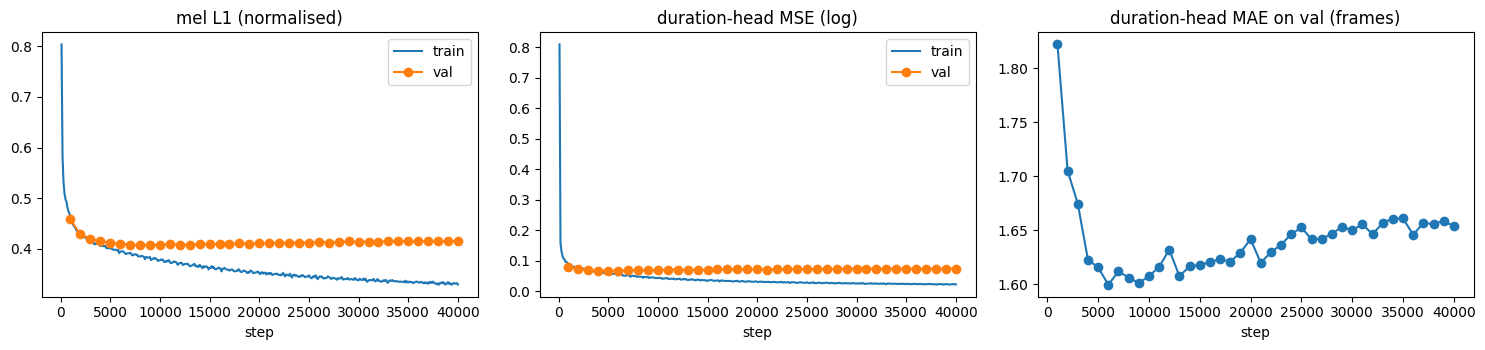

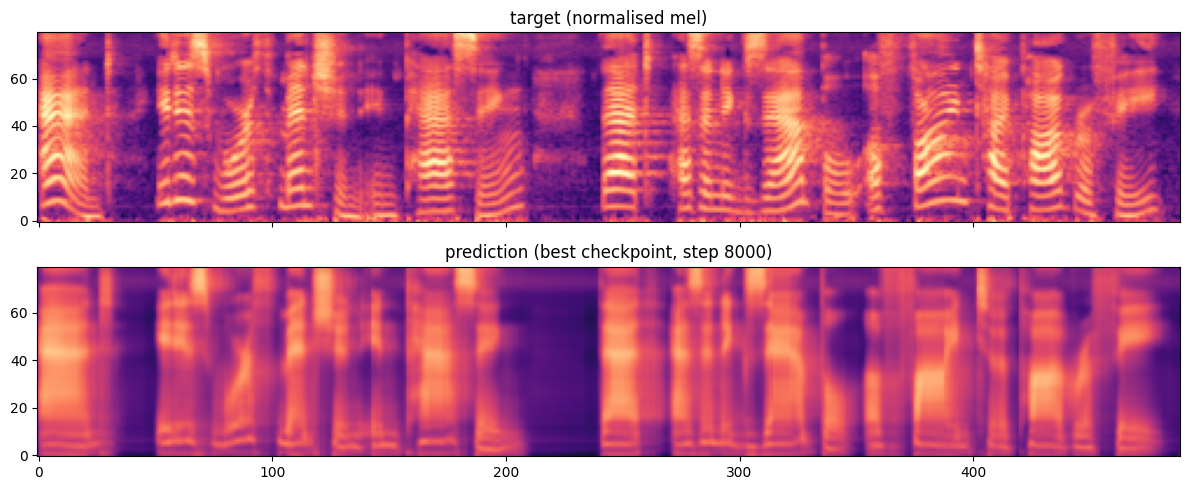

In [ ]:
tl, vl = pd.read_csv(TRAIN_LOG), pd.read_csv(VAL_LOG)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(tl.step, tl.mel_l1, label='train'); ax[0].plot(vl.step, vl.val_mel_l1, 'o-', label='val'); ax[0].set_title('mel L1 (normalised)'); ax[0].legend()
ax[1].plot(tl.step, tl.dur_mse, label='train'); ax[1].plot(vl.step, vl.val_dur_mse, 'o-', label='val'); ax[1].set_title('duration-head MSE (log)'); ax[1].legend()
ax[2].plot(vl.step, vl.val_dur_mae_frames, 'o-'); ax[2].set_title('duration-head MAE on val (frames)')
for a in ax: a.set_xlabel('step')
fig.tight_layout(); fig.savefig(os.path.join(RESULTS, '12_curves.png'), dpi=140); plt.show()

ck = torch.load(BEST, map_location=DEV, weights_only=False); model.load_state_dict(ck['model']); model.eval()
b = to_dev(collate([va[0]]))
with torch.no_grad(): o = model(b['tok'], b['stress'], dur=b['dur'])
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
for a, m, t in zip(ax, (b['mel'][0], o['mel'][0]), ('target (normalised mel)', f'prediction (best checkpoint, step {ck["step"]})')):
    a.imshow(m.cpu().numpy().T, origin='lower', aspect='auto', cmap='magma', vmin=-3, vmax=3); a.set_title(t)
fig.tight_layout(); fig.savefig(os.path.join(RESULTS, '12_val_example.png'), dpi=140); plt.show()

## What to check before moving on
1. Validation mel L1 keeps falling and then flattens; the train and val curves are not far apart (a big gap means overfitting).
2. The prediction plot shows clear harmonic bands in voiced regions, a little blurry compared with the target. A blurry-but-structured mel is normal for this model class.
3. Save `12_curves.png` for the report. `best.pt` is on Drive; do **not** commit checkpoints to GitHub.

**Next:** notebook 13 checks the vocoder (copy-synthesis of real clips) so we know it works before judging our own model.